# Downsampling code test

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from hmp_utils.motion.mocap_processor import MocapLoader, DownsampleMethod
from hmp_utils.motion.body_models_constants import SmplConstants

# plot params
joint_id_to_plot = 10
aa_element_to_plot = 0
mocap_filepath = "./example_mocaps/walking_poses.npz"
joints_to_use = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 12, 13, 14, 16, 17, 18, 19, 20, 21]
fig_opts = {"dpi": 200, "figsize": (10, 4)}

## Slerp vs Decimation / Resampling

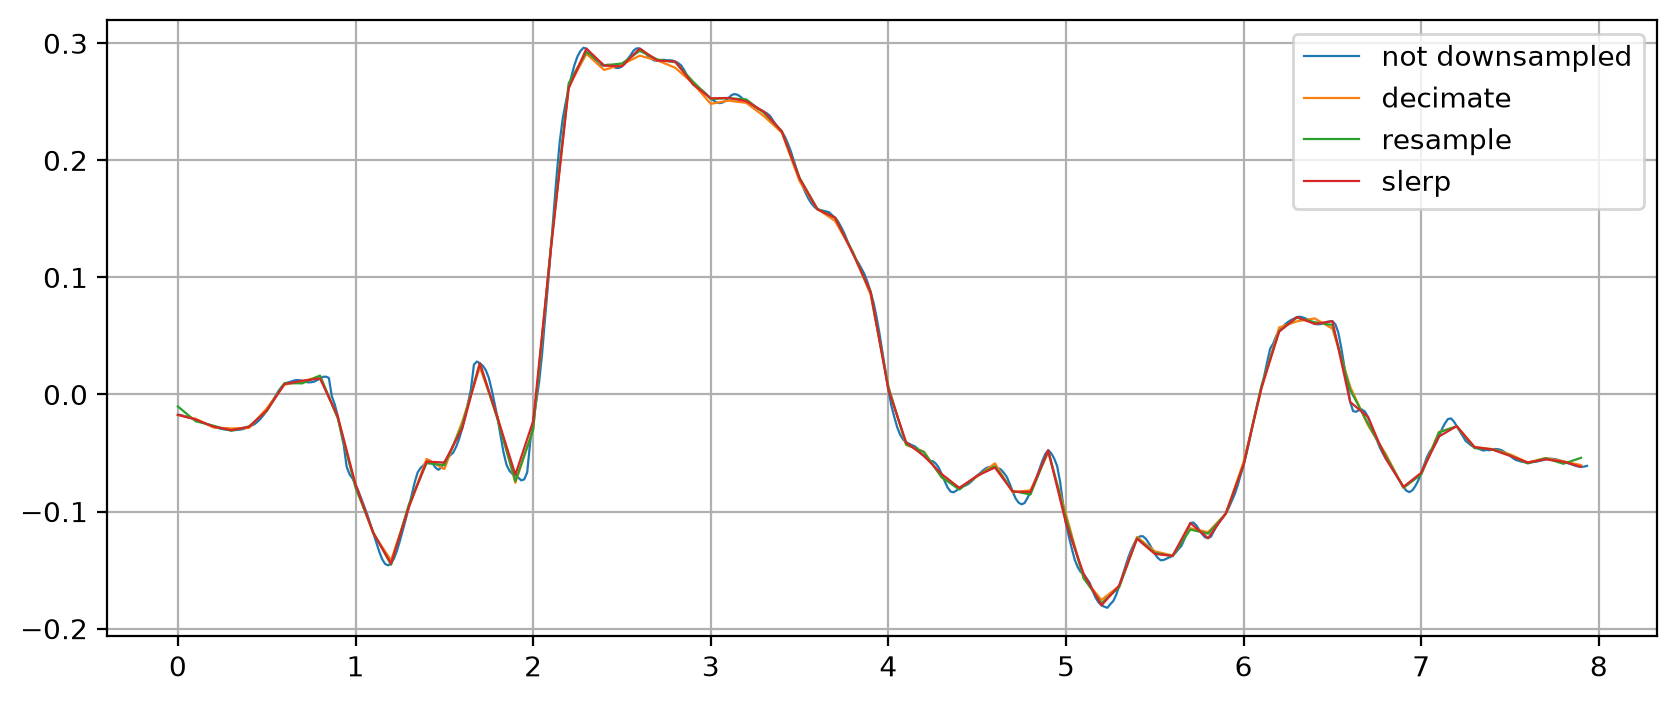

In [2]:
fig, ax = plt.subplots(**fig_opts)
target_framerate = 10
downsample_methods = [
    DownsampleMethod.NONE,
    DownsampleMethod.DECIMATE,
    DownsampleMethod.RESAMPLE,
    DownsampleMethod.SLERP,
]
downsample_methods_names = ["not downsampled", "decimate", "resample", "slerp"]


for idx, method in enumerate(downsample_methods):
    mocap_loader = MocapLoader(
        body_model_type=SmplConstants.BODY_MODEL_TYPE, keypoint_ids_to_load=joints_to_use, target_framerate=target_framerate, downsampling_method=method
    )
    mocap_data = mocap_loader.load_mocap(mocap_filepath)
    assert mocap_data is not None

    x_axis = np.arange(mocap_data.rots.shape[0])
    x_axis = x_axis / mocap_data.framerate

    ax.plot(
        x_axis,
        mocap_data.rots[:, joint_id_to_plot, aa_element_to_plot],
        label=f"{downsample_methods_names[idx]}",
        linewidth=0.8,
    )

    plt.plot()

ax.legend()
plt.grid()
plt.show()